<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/SIMULASI_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# ================================================================
# FILE 5 — STRONG SPATIAL DEPENDENCE
# rho = 0.80
# GRID10 x GRID10
#
# CELL 1 — PERSIAPAN DATA + W + ESF
#
# DATA TIDAK DIBANGKITKAN ULANG
# HANYA MENGAMBIL rho = 0.80 DARI FILE 1
# ================================================================

import os
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

warnings.filterwarnings("ignore")


# ================================================================
# 1. KONFIGURASI
# ================================================================

RHO_STRONG = 0.80
STRENGTH_STRONG = "Strong"

REPO_URL = "https://github.com/haniyathul/TESIS-HANIY.git"
REPO_DIR = Path("/content/TESIS-HANIY")


# ================================================================
# 2. CLONE REPOSITORY
# ================================================================

if not REPO_DIR.exists():

    print("📥 Clone repository...")

    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            str(REPO_DIR)
        ],
        check=True
    )

else:

    print("✅ Repository sudah tersedia")


DATA_DIR = REPO_DIR / "data"
WEIGHT_DIR = REPO_DIR / "weights"
ESF_DIR = REPO_DIR / "esf"


# ================================================================
# 3. GOOGLE DRIVE
# ================================================================

from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")


CHECKPOINT_DIR_STRONG10 = Path(
    "/content/drive/MyDrive/"
    "HANIY_CHECKPOINTS/"
    "FILE5_STRONG/"
    "GRID10"
)

CHECKPOINT_DIR_STRONG10.mkdir(
    parents=True,
    exist_ok=True
)


# ================================================================
# 4. PREDICTOR
# ================================================================

PREDICTOR_COLS_STRONG10 = (
    ["X_spatial"]
    +
    [f"X{i}" for i in range(1, 20)]
)

assert len(PREDICTOR_COLS_STRONG10) == 20


# ================================================================
# 5. LOAD DATA GRID10
# ================================================================

DATA_FILE_STRONG10 = DATA_DIR / "DATA_GRID10.csv"

assert DATA_FILE_STRONG10.exists(), (
    f"❌ Tidak ditemukan: {DATA_FILE_STRONG10}"
)

df_all = pd.read_csv(
    DATA_FILE_STRONG10
)


# ================================================================
# 6. FILTER rho = 0.80
# ================================================================

DATA_STRONG_GRID10 = (

    df_all[
        np.isclose(
            df_all["Rho"].astype(float),
            RHO_STRONG
        )
    ]

    .copy()
)


# ================================================================
# 7. W KEY
# ================================================================

def make_w_key_strong10(value):

    s = str(value).upper()

    if "KNN" in s:
        return "KNN5"

    if "DIST" in s:
        return "DISTANCE"

    if "IDW" in s:
        return "IDW"

    raise ValueError(
        f"W tidak dikenali: {value}"
    )


DATA_STRONG_GRID10["W_Key"] = (

    DATA_STRONG_GRID10[
        "W_Method"
    ]

    .apply(
        make_w_key_strong10
    )
)


DATA_STRONG_GRID10 = (

    DATA_STRONG_GRID10
    .sort_values(
        [
            "Scenario_ID",
            "Location_ID"
        ]
    )
    .reset_index(drop=True)
)


# ================================================================
# 8. SCENARIO
# ================================================================

SCENARIO_IDS_STRONG_GRID10 = (

    DATA_STRONG_GRID10[
        "Scenario_ID"
    ]

    .drop_duplicates()

    .tolist()
)


assert len(
    SCENARIO_IDS_STRONG_GRID10
) == 18


assert len(
    DATA_STRONG_GRID10
) == 1800


sizes = (

    DATA_STRONG_GRID10
    .groupby("Scenario_ID")
    .size()
)


assert (sizes == 100).all()

assert np.allclose(
    DATA_STRONG_GRID10["Rho"],
    0.80
)


# ================================================================
# 9. CARI NPZ
# ================================================================

def find_grid10_npz(
    folder,
    method
):

    candidates = []

    for f in Path(folder).glob("*.npz"):

        name = f.name.upper()

        if "GRID10" not in name:
            continue

        if method == "KNN5":
            ok = "KNN" in name

        elif method == "DISTANCE":
            ok = "DIST" in name

        elif method == "IDW":
            ok = "IDW" in name

        else:
            ok = False

        if ok:
            candidates.append(f)

    assert candidates, (
        f"❌ GRID10 {method} tidak ditemukan "
        f"di {folder}"
    )

    return sorted(candidates)[0]


# ================================================================
# 10. LOAD W ASLI
# ================================================================

def load_W_strong10(path):

    try:

        return (
            sp.load_npz(path)
            .tocsr()
            .astype(float)
        )

    except Exception:

        obj = np.load(
            path,
            allow_pickle=True
        )

        for key in obj.files:

            arr = np.asarray(
                obj[key]
            )

            if (
                arr.ndim == 2
                and
                arr.shape == (100, 100)
            ):

                return sp.csr_matrix(
                    arr.astype(float)
                )

    raise ValueError(
        f"❌ W tidak berhasil dibaca: {path}"
    )


# ================================================================
# 11. LOAD ESF ASLI
# ================================================================

def load_ESF_strong10(path):

    obj = np.load(
        path,
        allow_pickle=True
    )

    E = None
    eig = None

    # eigenvectors
    for key in [
        "eigenvectors",
        "eigenvector",
        "EV",
        "E",
        "vectors"
    ]:

        if key in obj.files:

            arr = np.asarray(
                obj[key]
            )

            if arr.ndim == 2:
                E = arr
                break


    if E is None:

        for key in obj.files:

            arr = np.asarray(
                obj[key]
            )

            if (
                arr.ndim == 2
                and
                (
                    arr.shape[0] == 100
                    or
                    arr.shape[1] == 100
                )
            ):

                E = arr
                break


    assert E is not None


    if E.shape[0] != 100:
        E = E.T


    # eigenvalues
    for key in [
        "eigenvalues",
        "eigenvalue",
        "values",
        "evals",
        "lambda"
    ]:

        if key in obj.files:

            arr = np.asarray(
                obj[key]
            ).reshape(-1)

            if len(arr) == E.shape[1]:
                eig = arr
                break


    if eig is None:

        for key in obj.files:

            arr = np.asarray(
                obj[key]
            )

            if (
                arr.ndim == 1
                and
                len(arr) == E.shape[1]
            ):

                eig = arr
                break


    assert eig is not None

    assert E.shape == (100, 99)

    return (
        E.astype(np.float32),
        eig.astype(float)
    )


# ================================================================
# 12. LOAD 3 W + 3 ESF
# ================================================================

W_STRONG10 = {}
ESF_STRONG10 = {}


for method in [
    "KNN5",
    "DISTANCE",
    "IDW"
]:

    w_file = find_grid10_npz(
        WEIGHT_DIR,
        method
    )

    esf_file = find_grid10_npz(
        ESF_DIR,
        method
    )


    W_STRONG10[method] = (
        load_W_strong10(
            w_file
        )
    )


    (
        E,
        eigenvalues
    ) = load_ESF_strong10(
        esf_file
    )


    ESF_STRONG10[method] = {

        "E":
            E,

        "eigenvalues":
            eigenvalues
    }


    print(
        f"✅ {method:8s}"
        f" | W={W_STRONG10[method].shape}"
        f" | EV={E.shape[1]}"
        f" | Positive EV="
        f"{np.sum(eigenvalues > 0)}"
    )


# ================================================================
# 13. VALIDASI FINAL
# ================================================================

print(
    "\n"
    + "=" * 80
)

print(
    "FILE 5 — STRONG GRID10 DATA READY"
)

print(
    "=" * 80
)

print(
    "Grid             : 10x10"
)

print(
    "N                : 100"
)

print(
    "Rho              :",
    DATA_STRONG_GRID10[
        "Rho"
    ].unique()
)

print(
    "Strength         : Strong"
)

print(
    "Scenario         :",
    len(
        SCENARIO_IDS_STRONG_GRID10
    )
)

print(
    "Rows             :",
    len(
        DATA_STRONG_GRID10
    )
)

print(
    "Predictor        :",
    len(
        PREDICTOR_COLS_STRONG10
    )
)

print(
    "W               :",
    list(
        W_STRONG10.keys()
    )
)

print(
    "ESF             : 99 EV / W"
)

print(
    "\n✅ FILE 5 STRONG GRID10 — PREPARATION PASS"
)

📥 Clone repository...
Mounted at /content/drive
✅ KNN5     | W=(100, 100) | EV=99 | Positive EV=36
✅ DISTANCE | W=(100, 100) | EV=99 | Positive EV=32
✅ IDW      | W=(100, 100) | EV=99 | Positive EV=21

FILE 5 — STRONG GRID10 DATA READY
Grid             : 10x10
N                : 100
Rho              : [0.8]
Strength         : Strong
Scenario         : 18
Rows             : 1800
Predictor        : 20
W               : ['KNN5', 'DISTANCE', 'IDW']
ESF             : 99 EV / W

✅ FILE 5 STRONG GRID10 — PREPARATION PASS


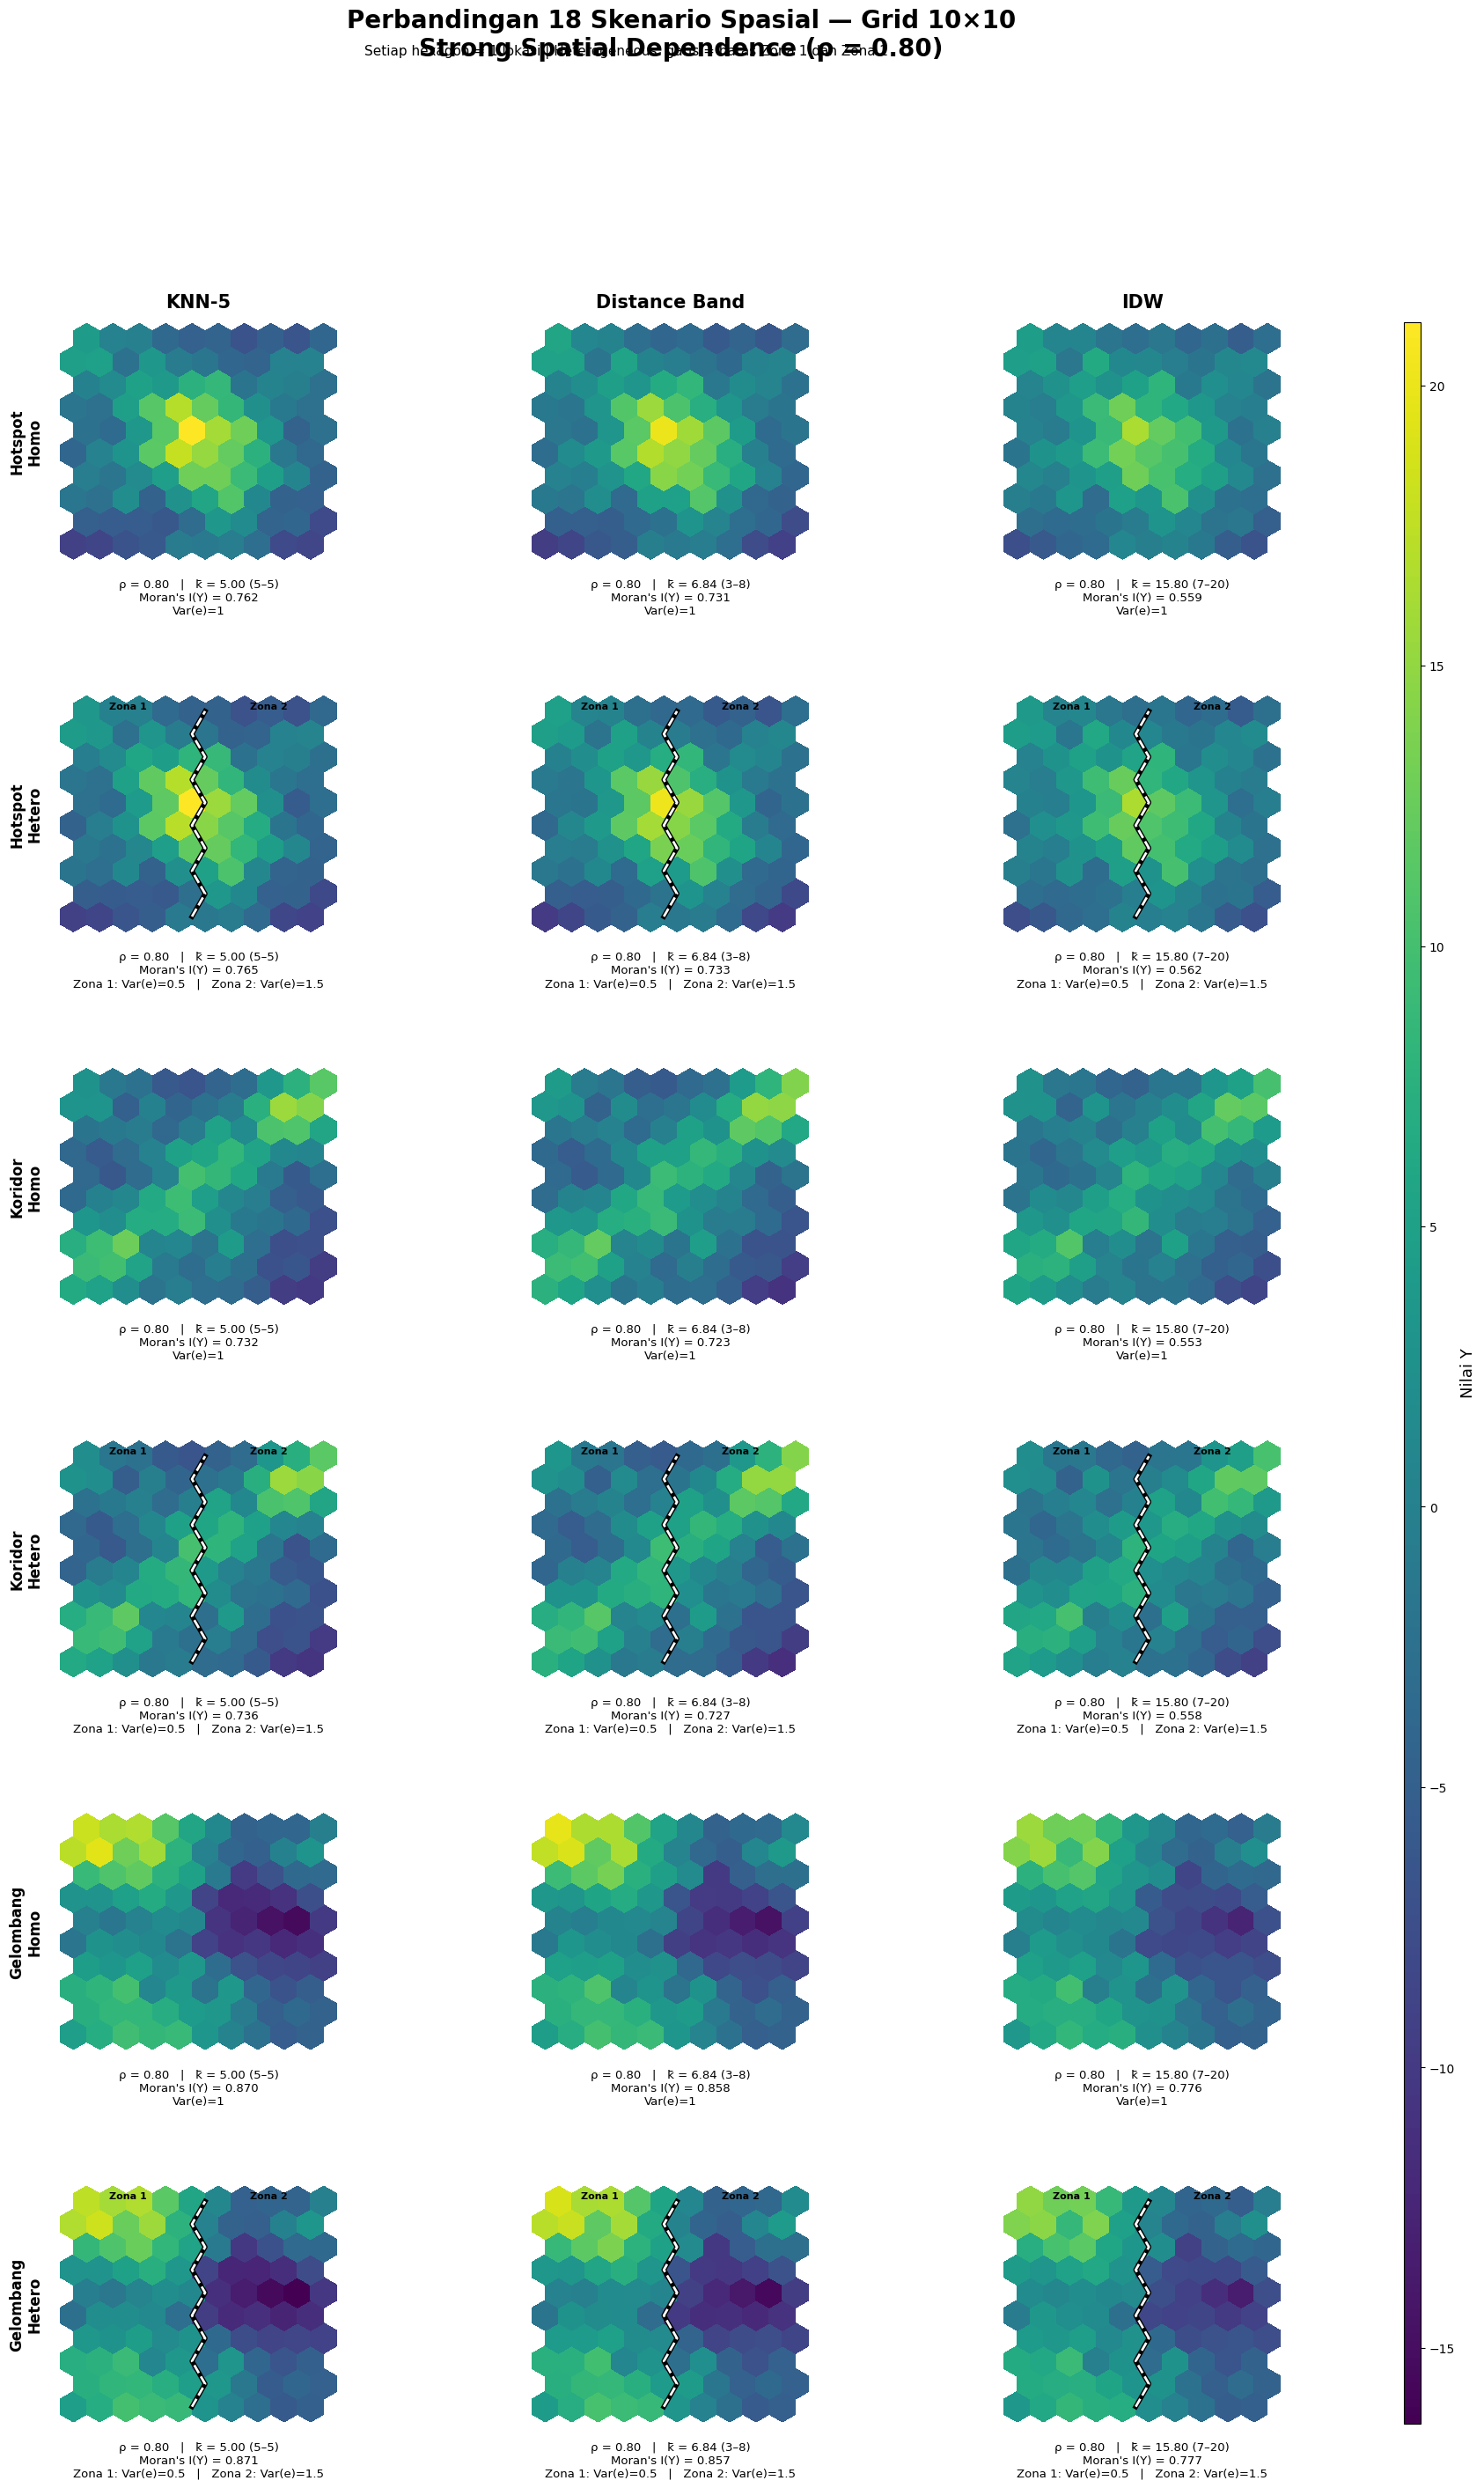


✅ Visualisasi Strong Grid10 selesai
✅ Semua rho = 0.80
/content/FILE5_STRONG_GRID10/VISUALISASI/HEXAGON_18_STRONG_GRID10.png


In [4]:
# ================================================================
# FILE 5 — STRONG rho = 0.80
# GRID10
#
# VISUALISASI 18 SKENARIO
# 3 KOLOM x 6 BARIS
#
# 1 lokasi = 1 hexagon
# HETERO:
# Zona 1 : x <= 0.5 → Var(e)=0.5
# Zona 2 : x >  0.5 → Var(e)=1.5
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.sparse as sp

from pathlib import Path
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.gridspec import GridSpec


# ================================================================
# 1. DATA
# ================================================================

df = DATA_STRONG_GRID10.copy()

assert len(df) == 1800
assert df["Scenario_ID"].nunique() == 18
assert np.allclose(df["Rho"], 0.80)


# ================================================================
# 2. LABEL
# ================================================================

def pattern_plot_s10(x):

    s = str(x).upper()

    if "HOT" in s:
        return "Hotspot"

    if "KOR" in s or "COR" in s:
        return "Koridor"

    if "GEL" in s or "WAVE" in s:
        return "Gelombang"

    return str(x)


def w_plot_s10(x):

    s = str(x).upper()

    if "KNN" in s:
        return "KNN-5"

    if "DIST" in s:
        return "Distance Band"

    if "IDW" in s:
        return "IDW"

    return str(x)


def error_plot_s10(x):

    s = str(x).upper()

    if "HET" in s:
        return "Heterogeneous"

    return "Homogeneous"


df["Pattern_plot"] = (
    df["Pattern"].apply(
        pattern_plot_s10
    )
)

df["W_plot"] = (
    df["W_Method"].apply(
        w_plot_s10
    )
)

df["Error_plot"] = (
    df["Error_Structure"].apply(
        error_plot_s10
    )
)


PATTERNS = [
    "Hotspot",
    "Koridor",
    "Gelombang"
]

ERRORS = [
    "Homogeneous",
    "Heterogeneous"
]

W_METHODS = [
    "KNN-5",
    "Distance Band",
    "IDW"
]

ROWS = [
    (p, e)
    for p in PATTERNS
    for e in ERRORS
]


# ================================================================
# 3. TETANGGA DARI W ASLI
# ================================================================

def neighbor_counts_s10(W):

    if sp.issparse(W):

        return np.diff(
            W.tocsr().indptr
        )

    return np.count_nonzero(
        np.asarray(W),
        axis=1
    )


# ================================================================
# 4. MORAN I
# ================================================================

def moran_I_s10(
    y,
    W
):

    y = np.asarray(
        y,
        dtype=float
    )

    z = y - np.mean(y)

    denom = float(
        z @ z
    )

    if denom <= 0:
        return np.nan

    Wz = W @ z

    S0 = float(
        W.sum()
    )

    n = len(z)

    return float(

        (n / S0)

        *

        (
            float(z @ Wz)
            / denom
        )
    )


# ================================================================
# 5. WARNA GLOBAL
# ================================================================

VALUE_COL = "Y"

vmin = float(
    df["Y"].min()
)

vmax = float(
    df["Y"].max()
)

norm = mpl.colors.Normalize(
    vmin=vmin,
    vmax=vmax
)

cmap = plt.get_cmap(
    "viridis"
)


# ================================================================
# 6. HEXAGON RAPAT
# ================================================================

def draw_hex_s10(
    ax,
    data
):

    d = (
        data
        .sort_values("Location_ID")
        .reset_index(drop=True)
    )

    xvals = np.sort(
        d["X_norm"].unique()
    )

    yvals = np.sort(
        d["Y_norm"].unique()
    )

    x_to_col = {
        float(v): i
        for i, v in enumerate(xvals)
    }

    y_to_row = {
        float(v): i
        for i, v in enumerate(yvals)
    }


    R = 1.0

    width = (
        np.sqrt(3) * R
    )

    dy = 1.5 * R


    rel = np.array([

        [0, R],

        [
            np.sqrt(3)/2 * R,
            0.5 * R
        ],

        [
            np.sqrt(3)/2 * R,
            -0.5 * R
        ],

        [0, -R],

        [
            -np.sqrt(3)/2 * R,
            -0.5 * R
        ],

        [
            -np.sqrt(3)/2 * R,
            0.5 * R
        ]
    ])


    patches = []
    values = []


    for _, obs in d.iterrows():

        col = x_to_col[
            float(obs["X_norm"])
        ]

        row = y_to_row[
            float(obs["Y_norm"])
        ]


        offset = (
            width / 2
            if row % 2 == 1
            else 0
        )


        xc = (
            col * width
            + offset
        )

        yc = (
            row * dy
        )


        vertices = (
            rel
            +
            np.array([
                xc,
                yc
            ])
        )


        patches.append(
            Polygon(
                vertices,
                closed=True
            )
        )

        values.append(
            float(
                obs["Y"]
            )
        )


    collection = PatchCollection(

        patches,

        cmap=cmap,

        norm=norm,

        edgecolors="none",

        linewidths=0,

        antialiaseds=False
    )


    collection.set_array(
        np.asarray(values)
    )


    ax.add_collection(
        collection
    )


    max_x = (
        9 * width
        + width / 2
    )

    max_y = (
        9 * dy
    )


    ax.set_xlim(
        -width * .6,
        max_x + width * .6
    )

    ax.set_ylim(
        -R * 1.1,
        max_y + R * 1.1
    )

    ax.set_aspect("equal")

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


    return {

        "width":
            width,

        "dy":
            dy
    }


# ================================================================
# 7. GARIS ZONA HETERO
# ================================================================

def draw_zone_boundary_s10(
    ax,
    geom
):

    width = geom["width"]
    dy = geom["dy"]

    bx = []
    by = []

    # Grid10:
    # kolom 0-4 = x <= .5
    # kolom 5-9 = x > .5
    for row in range(10):

        offset = (
            width / 2
            if row % 2 == 1
            else 0
        )

        left_center = (
            4 * width
            + offset
        )

        right_center = (
            5 * width
            + offset
        )

        bx.append(
            (
                left_center
                + right_center
            ) / 2
        )

        by.append(
            row * dy
        )


    # outline hitam
    ax.plot(
        bx,
        by,
        linewidth=4,
        color="black",
        zorder=20
    )

    # garis putih putus-putus
    ax.plot(
        bx,
        by,
        linewidth=2,
        color="white",
        linestyle="--",
        zorder=21
    )


    ax.text(
        .25,
        .97,
        "Zona 1",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=8,
        fontweight="bold"
    )

    ax.text(
        .75,
        .97,
        "Zona 2",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=8,
        fontweight="bold"
    )


# ================================================================
# 8. FIGURE
# ================================================================

fig = plt.figure(
    figsize=(21, 31)
)


gs = GridSpec(

    6,
    4,

    figure=fig,

    width_ratios=[
        1,
        1,
        1,
        .04
    ],

    wspace=.16,

    hspace=.56
)


axes = np.empty(
    (6, 3),
    dtype=object
)


for r in range(6):

    for c in range(3):

        axes[r, c] = (
            fig.add_subplot(
                gs[r, c]
            )
        )


cax = fig.add_subplot(
    gs[:, 3]
)


INFO_SPASIAL_STRONG10 = []


# ================================================================
# 9. 18 SKENARIO
# ================================================================

for r, (
    pattern,
    error
) in enumerate(ROWS):


    for c, wmethod in enumerate(
        W_METHODS
    ):


        ax = axes[r, c]


        d = (

            df[
                (
                    df["Pattern_plot"]
                    == pattern
                )
                &
                (
                    df["Error_plot"]
                    == error
                )
                &
                (
                    df["W_plot"]
                    == wmethod
                )
            ]

            .sort_values(
                "Location_ID"
            )

            .reset_index(
                drop=True
            )
        )


        assert len(d) == 100


        # rho LANGSUNG dari data
        rho_values = (
            d["Rho"]
            .astype(float)
            .unique()
        )

        assert len(rho_values) == 1

        rho = float(
            rho_values[0]
        )

        assert np.isclose(
            rho,
            0.80
        )


        w_key = str(
            d["W_Key"].iloc[0]
        )

        W = W_STRONG10[
            w_key
        ]


        counts = neighbor_counts_s10(
            W
        )

        k_mean = float(
            counts.mean()
        )

        k_min = int(
            counts.min()
        )

        k_max = int(
            counts.max()
        )


        moran_y = moran_I_s10(

            d["Y"].to_numpy(
                dtype=float
            ),

            W
        )


        geom = draw_hex_s10(
            ax,
            d
        )


        # hetero → garis zona
        if error == "Heterogeneous":

            draw_zone_boundary_s10(
                ax,
                geom
            )


        if r == 0:

            ax.set_title(

                wmethod,

                fontsize=15,

                fontweight="bold",

                pad=12
            )


        if c == 0:

            err_short = (
                "Homo"
                if error == "Homogeneous"
                else "Hetero"
            )

            ax.set_ylabel(

                f"{pattern}\n"
                f"{err_short}",

                fontsize=12,

                fontweight="bold",

                labelpad=12
            )


        if error == "Heterogeneous":

            info = (

                f"ρ = {rho:.2f}   |   "
                f"k̄ = {k_mean:.2f} "
                f"({k_min}–{k_max})"
                "\n"
                f"Moran's I(Y) = {moran_y:.3f}"
                "\n"
                "Zona 1: Var(e)=0.5   |   "
                "Zona 2: Var(e)=1.5"
            )

        else:

            info = (

                f"ρ = {rho:.2f}   |   "
                f"k̄ = {k_mean:.2f} "
                f"({k_min}–{k_max})"
                "\n"
                f"Moran's I(Y) = {moran_y:.3f}"
                "\n"
                "Var(e)=1"
            )


        ax.text(

            .5,
            -.075,

            info,

            transform=ax.transAxes,

            ha="center",

            va="top",

            fontsize=9.5
        )


        INFO_SPASIAL_STRONG10.append({

            "Pattern":
                pattern,

            "Error":
                error,

            "W":
                wmethod,

            "Rho":
                rho,

            "Mean_Neighbors":
                k_mean,

            "Min_Neighbors":
                k_min,

            "Max_Neighbors":
                k_max,

            "Moran_I_Y":
                moran_y
        })


# ================================================================
# 10. COLORBAR
# ================================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    cax=cax
)

cbar.set_label(
    "Nilai Y",
    fontsize=13
)


# ================================================================
# 11. TITLE
# ================================================================

fig.suptitle(

    "Perbandingan 18 Skenario Spasial — Grid 10×10\n"
    "Strong Spatial Dependence (ρ = 0.80)",

    fontsize=20,

    fontweight="bold",

    y=.995
)


fig.text(

    .47,

    .978,

    (
        "Setiap hexagon = 1 lokasi | "
        "Heterogeneous: garis = batas Zona 1 dan Zona 2"
    ),

    ha="center",

    fontsize=11
)


# ================================================================
# 12. SAVE
# ================================================================

VISUAL_DIR_STRONG10 = Path(
    "/content/FILE5_STRONG_GRID10/VISUALISASI"
)

VISUAL_DIR_STRONG10.mkdir(
    parents=True,
    exist_ok=True
)


PNG_STRONG10 = (
    VISUAL_DIR_STRONG10
    / "HEXAGON_18_STRONG_GRID10.png"
)


CSV_STRONG10 = (
    VISUAL_DIR_STRONG10
    / "IDENTITAS_SPASIAL_18_STRONG_GRID10.csv"
)


pd.DataFrame(
    INFO_SPASIAL_STRONG10
).to_csv(
    CSV_STRONG10,
    index=False
)


plt.savefig(
    PNG_STRONG10,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "\n✅ Visualisasi Strong Grid10 selesai"
)

print(
    "✅ Semua rho = 0.80"
)

print(
    PNG_STRONG10
)

In [5]:
# ================================================================
# FILE 5 — STRONG rho = 0.80
# GRID10
#
# PEMODELAN 5 METODE — SATU CELL
#
# 1. XGBoost
# 2. ESF-XGBoost Moran
# 3. ESF-XGBoost LASSO
# 4. ESF-XGBoost Stepwise
#    Candidate = POSITIVE EV ONLY
# 5. ESF-XGBoost SHAP
#    Candidate = ALL 99 EV
#
# OUTER CV = 5 spatial fold
# INNER CV = 3 spatial fold
# HYPERPARAMETER = 18
# CHECKPOINT = SETIAP OUTER FOLD
# ================================================================

import os
import pickle

import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path

from xgboost import XGBRegressor

from sklearn.cluster import KMeans
from sklearn.linear_model import LassoCV

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# ================================================================
# 1. CEK OBJEK
# ================================================================

assert "DATA_STRONG_GRID10" in globals()
assert "SCENARIO_IDS_STRONG_GRID10" in globals()
assert "ESF_STRONG10" in globals()
assert "CHECKPOINT_DIR_STRONG10" in globals()


DATA_S10 = DATA_STRONG_GRID10.copy()

SCENARIOS_S10 = (
    SCENARIO_IDS_STRONG_GRID10
)


# ================================================================
# 2. MODEL
# ================================================================

MODELS_S10 = [

    "XGBoost",

    "ESF-XGBoost Moran",

    "ESF-XGBoost LASSO",

    "ESF-XGBoost Stepwise",

    "ESF-XGBoost SHAP"
]


# ================================================================
# 3. OUTER SPATIAL CV
# ================================================================

first_sid = SCENARIOS_S10[0]

base_location = (

    DATA_S10[
        DATA_S10[
            "Scenario_ID"
        ] == first_sid
    ]

    .sort_values(
        "Location_ID"
    )

    .reset_index(drop=True)
)


base_coords = (

    base_location[
        [
            "X_norm",
            "Y_norm"
        ]
    ]

    .to_numpy()
)


OUTER_LABEL_S10 = KMeans(

    n_clusters=5,

    random_state=2026,

    n_init=20

).fit_predict(
    base_coords
)


fold_map = dict(

    zip(

        base_location[
            "Location_ID"
        ],

        OUTER_LABEL_S10
    )
)


DATA_S10[
    "Outer_Fold"
] = (

    DATA_S10[
        "Location_ID"
    ]

    .map(
        fold_map
    )

    .astype(int)
)


# ================================================================
# 4. 18 HYPERPARAMETER
# ================================================================

hyper_rows = []

counter = 1


for n_estimators in [
    200,
    300
]:

    for learning_rate in [
        .03,
        .05,
        .10
    ]:

        for max_depth in [
            2,
            3,
            4
        ]:

            hyper_rows.append({

                "Hyper_ID":
                    f"H{counter:02d}",

                "n_estimators":
                    n_estimators,

                "learning_rate":
                    learning_rate,

                "max_depth":
                    max_depth
            })

            counter += 1


HYPER_GRID_STRONG10 = pd.DataFrame(
    hyper_rows
)


assert len(
    HYPER_GRID_STRONG10
) == 18


# ================================================================
# 5. XGBOOST FIXED
# ================================================================

XGB_FIXED_S10 = {

    "objective":
        "reg:squarederror",

    "min_child_weight":
        1,

    "subsample":
        .8,

    "colsample_bytree":
        .8,

    "reg_alpha":
        0,

    "reg_lambda":
        1,

    "gamma":
        0,

    "tree_method":
        "hist",

    "eval_metric":
        "rmse",

    "random_state":
        2026,

    "n_jobs":
        -1
}


def make_xgb_s10(cfg):

    return XGBRegressor(

        n_estimators=int(
            cfg["n_estimators"]
        ),

        learning_rate=float(
            cfg["learning_rate"]
        ),

        max_depth=int(
            cfg["max_depth"]
        ),

        **XGB_FIXED_S10
    )


def rmse_s10(
    y,
    pred
):

    return float(

        np.sqrt(

            mean_squared_error(
                y,
                pred
            )
        )
    )


# ================================================================
# 6. INNER SPATIAL CV
# ================================================================

def inner_fold_s10(
    coords
):

    return KMeans(

        n_clusters=3,

        random_state=2026,

        n_init=20

    ).fit_predict(
        coords
    )


# ================================================================
# 7. TUNING
# ================================================================

def tune_xgb_s10(
    X,
    y,
    labels
):

    results = []


    for _, hp in (
        HYPER_GRID_STRONG10
        .iterrows()
    ):

        cfg = hp.to_dict()

        scores = []


        for fold in sorted(
            np.unique(labels)
        ):

            tr = labels != fold
            va = labels == fold


            model = make_xgb_s10(
                cfg
            )

            model.fit(
                X[tr],
                y[tr]
            )


            pred = model.predict(
                X[va]
            )


            scores.append(
                rmse_s10(
                    y[va],
                    pred
                )
            )


        results.append({

            "Hyper_ID":
                cfg["Hyper_ID"],

            "RMSE":
                float(
                    np.mean(scores)
                ),

            "config":
                cfg
        })


    results = sorted(

        results,

        key=lambda z: (
            z["RMSE"],
            z["Hyper_ID"]
        )
    )


    best = results[0]


    return (

        best["Hyper_ID"],

        best["config"],

        best["RMSE"]
    )


# ================================================================
# 8. FINAL FIT
# ================================================================

def fit_final_s10(
    Xtr,
    ytr,
    Xte,
    labels
):

    (
        hid,
        cfg,
        cv_rmse
    ) = tune_xgb_s10(

        Xtr,
        ytr,
        labels
    )


    model = make_xgb_s10(
        cfg
    )


    model.fit(
        Xtr,
        ytr
    )


    pred = model.predict(
        Xte
    )


    return (
        pred,
        hid,
        cfg,
        cv_rmse
    )


# ================================================================
# 9. CROSS-FITTED BASELINE RESIDUAL
# ================================================================

def crossfit_residual_s10(
    X,
    y,
    labels,
    cfg
):

    pred = np.full(
        len(y),
        np.nan
    )


    for fold in sorted(
        np.unique(labels)
    ):

        tr = labels != fold
        va = labels == fold


        model = make_xgb_s10(
            cfg
        )


        model.fit(
            X[tr],
            y[tr]
        )


        pred[va] = model.predict(
            X[va]
        )


    assert not np.isnan(
        pred
    ).any()


    return (
        pred,
        y - pred
    )


# ================================================================
# 10. MORAN SELECTOR
# ================================================================

def select_moran_s10(
    eigenvalues
):

    eig = np.asarray(
        eigenvalues
    )


    positive = eig[
        eig > 0
    ]


    if len(positive) == 0:

        return np.array(
            [],
            dtype=int
        )


    threshold = (

        .25

        * np.max(
            positive
        )
    )


    return np.where(

        (eig > 0)

        &

        (eig >= threshold)

    )[0].astype(int)


# ================================================================
# 11. LASSO — ALL 99 EV
# ================================================================

def select_lasso_s10(
    E,
    residual,
    labels
):

    splits = []


    for fold in sorted(
        np.unique(labels)
    ):

        splits.append((

            np.where(
                labels != fold
            )[0],

            np.where(
                labels == fold
            )[0]
        ))


    model = LassoCV(

        cv=splits,

        fit_intercept=True,

        max_iter=50000,

        n_jobs=-1
    )


    model.fit(
        E,
        residual
    )


    selected = np.where(

        np.abs(
            model.coef_
        ) > 1e-8

    )[0]


    return (

        selected.astype(int),

        float(
            model.alpha_
        )
    )


# ================================================================
# 12. STEPWISE POSITIVE EV
# ================================================================

def subset_cv_rmse_s10(
    E,
    residual,
    labels,
    selected
):

    scores = []


    for fold in sorted(
        np.unique(labels)
    ):

        tr = labels != fold
        va = labels == fold


        ytr = residual[tr]
        yva = residual[va]


        if len(selected) == 0:

            pred = np.full(
                np.sum(va),
                np.mean(ytr)
            )


        else:

            Dtr = np.column_stack([

                np.ones(
                    np.sum(tr)
                ),

                E[tr][:, selected]
            ])


            Dva = np.column_stack([

                np.ones(
                    np.sum(va)
                ),

                E[va][:, selected]
            ])


            beta = np.linalg.lstsq(

                Dtr,
                ytr,
                rcond=None

            )[0]


            pred = (
                Dva @ beta
            )


        scores.append(
            rmse_s10(
                yva,
                pred
            )
        )


    return float(
        np.mean(scores)
    )


def candidate_scores_s10(
    E,
    residual,
    labels,
    selected,
    remaining
):

    score_sum = np.zeros(
        len(remaining)
    )


    Erem = E[
        :,
        remaining
    ].astype(
        np.float64,
        copy=False
    )


    folds = sorted(
        np.unique(labels)
    )


    for fold in folds:

        tr = labels != fold
        va = labels == fold


        ytr = residual[tr].astype(
            np.float64,
            copy=False
        )


        yva = residual[va].astype(
            np.float64,
            copy=False
        )


        if len(selected) == 0:

            Dtr = np.ones(
                (
                    np.sum(tr),
                    1
                )
            )

            Dva = np.ones(
                (
                    np.sum(va),
                    1
                )
            )


        else:

            Dtr = np.column_stack([

                np.ones(
                    np.sum(tr)
                ),

                E[tr][:, selected]
            ])


            Dva = np.column_stack([

                np.ones(
                    np.sum(va)
                ),

                E[va][:, selected]
            ])


        beta_y = np.linalg.lstsq(

            Dtr,
            ytr,
            rcond=None

        )[0]


        base_pred = (
            Dva @ beta_y
        )


        residual_train = (

            ytr

            -

            Dtr @ beta_y
        )


        Xtr_rem = Erem[tr]
        Xva_rem = Erem[va]


        B = np.linalg.lstsq(

            Dtr,
            Xtr_rem,
            rcond=None

        )[0]


        Utr = (
            Xtr_rem
            - Dtr @ B
        )

        Uva = (
            Xva_rem
            - Dva @ B
        )


        denominator = np.sum(
            Utr * Utr,
            axis=0
        )


        numerator = (
            Utr.T
            @ residual_train
        )


        alpha = np.zeros_like(
            numerator
        )


        valid = (
            denominator > 1e-12
        )


        alpha[valid] = (

            numerator[valid]

            /

            denominator[valid]
        )


        pred_matrix = (

            base_pred[:, None]

            +

            Uva
            * alpha[None, :]
        )


        errors = (

            yva[:, None]

            -

            pred_matrix
        )


        score_sum += np.sqrt(

            np.mean(
                errors ** 2,
                axis=0
            )
        )


    return (
        score_sum
        / len(folds)
    )


def forward_stepwise_s10(
    E_positive,
    residual,
    labels,
    positive_original_idx
):

    selected_local = []

    remaining = list(
        range(
            E_positive.shape[1]
        )
    )


    current_rmse = subset_cv_rmse_s10(

        E_positive,
        residual,
        labels,
        []
    )


    while remaining:

        scores = candidate_scores_s10(

            E_positive,
            residual,
            labels,
            selected_local,
            remaining
        )


        best_pos = int(
            np.argmin(scores)
        )


        best_local = (
            remaining[
                best_pos
            ]
        )


        best_score = float(
            scores[
                best_pos
            ]
        )


        if (
            current_rmse
            -
            best_score
        ) <= 1e-10:

            break


        selected_local.append(
            best_local
        )


        remaining.pop(
            best_pos
        )


        current_rmse = (
            best_score
        )


    if not selected_local:

        selected_original = np.array(
            [],
            dtype=int
        )

    else:

        selected_original = (

            positive_original_idx[

                np.asarray(
                    selected_local,
                    dtype=int
                )
            ]
        )


    return (

        selected_original,

        float(
            current_rmse
        )
    )


# ================================================================
# 13. SHAP — ALL 99 EV
# ================================================================

def select_shap_s10(
    E,
    residual,
    labels
):

    (
        selector_hid,
        selector_cfg,
        selector_cv
    ) = tune_xgb_s10(

        E,
        residual,
        labels
    )


    selector = make_xgb_s10(
        selector_cfg
    )


    selector.fit(
        E,
        residual
    )


    shap_values = (

        selector
        .get_booster()
        .predict(

            xgb.DMatrix(E),

            pred_contribs=True
        )
    )[:, :-1]


    importance = np.mean(
        np.abs(shap_values),
        axis=0
    )


    total = float(
        importance.sum()
    )


    if total <= 0:

        selected = np.array(
            [],
            dtype=int
        )


    else:

        order = np.argsort(
            importance
        )[::-1]


        cumulative = (

            np.cumsum(
                importance[order]
            )

            / total
        )


        k = int(

            np.searchsorted(
                cumulative,
                .90
            )

            + 1
        )


        selected = (
            order[:k]
            .astype(int)
        )


    return (

        selected,

        selector_hid,

        selector_cv
    )


# ================================================================
# 14. CHECKPOINT
# ================================================================

CHECKPOINT_STRONG10 = (

    CHECKPOINT_DIR_STRONG10
    / "STRONG_GRID10_5MODEL.pkl"
)


VERSION_S10 = (
    "STRONG_GRID10_RHO080_5MODEL_V1"
)


def save_state_s10(
    state
):

    tmp = Path(
        str(CHECKPOINT_STRONG10)
        + ".tmp"
    )


    with open(
        tmp,
        "wb"
    ) as f:

        pickle.dump(

            state,
            f,

            protocol=
                pickle.HIGHEST_PROTOCOL
        )


    os.replace(
        tmp,
        CHECKPOINT_STRONG10
    )


def done_key_s10(
    model,
    sid,
    fold
):

    return (
        f"{model}"
        f"|||{sid}"
        f"|||{fold}"
    )


def baseline_key_s10(
    sid,
    fold
):

    return (
        f"{sid}"
        f"|||{fold}"
    )


# ================================================================
# 15. LOAD / CREATE STATE
# ================================================================

state = None


if CHECKPOINT_STRONG10.exists():

    try:

        with open(
            CHECKPOINT_STRONG10,
            "rb"
        ) as f:

            candidate = (
                pickle.load(f)
            )


        if (
            candidate.get(
                "version"
            )
            == VERSION_S10
        ):

            state = candidate

            print(
                "✅ RESUME CHECKPOINT"
            )

    except Exception:

        state = None


if state is None:

    state = {

        "version":
            VERSION_S10,

        "predictions":
            {},

        "done_keys":
            set(),

        "fold_rows":
            [],

        "baseline_config":
            {},

        "baseline_residual":
            {}
    }


for sid in SCENARIOS_S10:

    state[
        "predictions"
    ].setdefault(
        sid,
        {}
    )

    for model_name in MODELS_S10:

        state[
            "predictions"
        ][sid].setdefault(

            model_name,

            np.full(
                100,
                np.nan
            )
        )


# ================================================================
# 16. ANTI DUPLIKAT ROW
# ================================================================

def add_fold_row_s10(
    row
):

    state["fold_rows"] = [

        r

        for r in state["fold_rows"]

        if not (

            r["Scenario_ID"]
            == row["Scenario_ID"]

            and

            r["Model"]
            == row["Model"]

            and

            r["Fold"]
            == row["Fold"]
        )
    ]


    state[
        "fold_rows"
    ].append(
        row
    )


# ================================================================
# 17. MAIN — MODEL FIRST
# ================================================================

for model_no, model_name in enumerate(

    MODELS_S10,

    start=1
):


    print(
        "\n"
        + "=" * 80
    )

    print(
        f"MODEL {model_no}/5"
        f" — {model_name}"
    )

    print(
        "=" * 80
    )


    for scenario_no, sid in enumerate(

        SCENARIOS_S10,

        start=1
    ):


        d = (

            DATA_S10[
                DATA_S10[
                    "Scenario_ID"
                ] == sid
            ]

            .sort_values(
                "Location_ID"
            )

            .reset_index(drop=True)
        )


        X = (

            d[
                PREDICTOR_COLS_STRONG10
            ]

            .to_numpy(
                dtype=np.float32
            )
        )


        y = (

            d["Y"]

            .to_numpy(
                dtype=np.float32
            )
        )


        coords = (

            d[
                [
                    "X_norm",
                    "Y_norm"
                ]
            ]

            .to_numpy()
        )


        outer = (

            d["Outer_Fold"]

            .to_numpy(
                dtype=int
            )
        )


        w_key = str(
            d["W_Key"].iloc[0]
        )


        E = (

            ESF_STRONG10[
                w_key
            ]["E"]
        )


        eigenvalues = (

            ESF_STRONG10[
                w_key
            ]["eigenvalues"]
        )


        print(
            f"\nScenario "
            f"{scenario_no:02d}/18 "
            f"| {sid}"
        )


        for fold in range(5):

            key = done_key_s10(

                model_name,
                sid,
                fold
            )


            if key in state[
                "done_keys"
            ]:

                print(
                    f"  Fold "
                    f"{fold+1}/5 "
                    f"→ sudah selesai ✅"
                )

                continue


            train_idx = np.where(
                outer != fold
            )[0]

            test_idx = np.where(
                outer == fold
            )[0]


            Xtr = X[train_idx]
            Xte = X[test_idx]

            ytr = y[train_idx]
            yte = y[test_idx]

            Etr = E[train_idx]
            Ete = E[test_idx]


            inner_labels = inner_fold_s10(

                coords[
                    train_idx
                ]
            )


            bkey = baseline_key_s10(
                sid,
                fold
            )


            # ====================================================
            # BASELINE
            # ====================================================

            if model_name == "XGBoost":

                (
                    pred,
                    best_hid,
                    best_cfg,
                    best_cv
                ) = fit_final_s10(

                    Xtr,
                    ytr,
                    Xte,
                    inner_labels
                )


                state[
                    "baseline_config"
                ][bkey] = (
                    best_cfg
                )


                (
                    _,
                    residual_cf
                ) = crossfit_residual_s10(

                    Xtr,
                    ytr,
                    inner_labels,
                    best_cfg
                )


                state[
                    "baseline_residual"
                ][bkey] = (

                    residual_cf.astype(
                        np.float32
                    )
                )


                selected = np.array(
                    [],
                    dtype=int
                )

                lasso_alpha = np.nan
                step_cv = np.nan
                selector_hid = ""
                selector_cv = np.nan


            # ====================================================
            # MORAN
            # ====================================================

            elif model_name == "ESF-XGBoost Moran":

                selected = select_moran_s10(
                    eigenvalues
                )


                (
                    pred,
                    best_hid,
                    best_cfg,
                    best_cv
                ) = fit_final_s10(

                    np.hstack([
                        Xtr,
                        Etr[:, selected]
                    ]),

                    ytr,

                    np.hstack([
                        Xte,
                        Ete[:, selected]
                    ]),

                    inner_labels
                )


                lasso_alpha = np.nan
                step_cv = np.nan
                selector_hid = ""
                selector_cv = np.nan


            # ====================================================
            # LASSO / STEPWISE / SHAP
            # ====================================================

            else:

                if bkey in state[
                    "baseline_residual"
                ]:

                    residual_cf = np.asarray(

                        state[
                            "baseline_residual"
                        ][bkey]
                    )

                else:

                    cfg = state[
                        "baseline_config"
                    ][bkey]


                    (
                        _,
                        residual_cf
                    ) = crossfit_residual_s10(

                        Xtr,
                        ytr,
                        inner_labels,
                        cfg
                    )


                # LASSO
                if model_name == "ESF-XGBoost LASSO":

                    (
                        selected,
                        lasso_alpha
                    ) = select_lasso_s10(

                        Etr,
                        residual_cf,
                        inner_labels
                    )

                    step_cv = np.nan
                    selector_hid = ""
                    selector_cv = np.nan


                # STEPWISE
                elif model_name == "ESF-XGBoost Stepwise":

                    positive_idx = np.where(
                        eigenvalues > 0
                    )[0]


                    (
                        selected,
                        step_cv
                    ) = forward_stepwise_s10(

                        Etr[
                            :,
                            positive_idx
                        ],

                        residual_cf,

                        inner_labels,

                        positive_idx
                    )


                    lasso_alpha = np.nan
                    selector_hid = ""
                    selector_cv = np.nan


                # SHAP
                else:

                    (
                        selected,
                        selector_hid,
                        selector_cv
                    ) = select_shap_s10(

                        Etr,
                        residual_cf,
                        inner_labels
                    )


                    lasso_alpha = np.nan
                    step_cv = np.nan


                (
                    pred,
                    best_hid,
                    best_cfg,
                    best_cv
                ) = fit_final_s10(

                    np.hstack([
                        Xtr,
                        Etr[:, selected]
                    ]),

                    ytr,

                    np.hstack([
                        Xte,
                        Ete[:, selected]
                    ]),

                    inner_labels
                )


            # ====================================================
            # SAVE
            # ====================================================

            state[
                "predictions"
            ][sid][model_name][
                test_idx
            ] = pred


            fold_r2 = float(
                r2_score(
                    yte,
                    pred
                )
            )


            fold_rmse = rmse_s10(
                yte,
                pred
            )


            fold_mae = float(
                mean_absolute_error(
                    yte,
                    pred
                )
            )


            row = {

                "Scenario_ID":
                    sid,

                "Pattern":
                    d["Pattern"].iloc[0],

                "W_Method":
                    d["W_Method"].iloc[0],

                "Error_Structure":
                    d[
                        "Error_Structure"
                    ].iloc[0],

                "Rho":
                    0.80,

                "Fold":
                    fold + 1,

                "Model":
                    model_name,

                "Best_Hyper_ID":
                    best_hid,

                "Best_Inner_RMSE":
                    float(best_cv),

                "n_estimators":
                    int(
                        best_cfg[
                            "n_estimators"
                        ]
                    ),

                "learning_rate":
                    float(
                        best_cfg[
                            "learning_rate"
                        ]
                    ),

                "max_depth":
                    int(
                        best_cfg[
                            "max_depth"
                        ]
                    ),

                "N_EV_Selected":
                    int(
                        len(selected)
                    ),

                "LASSO_Alpha":
                    lasso_alpha,

                "StepCV_RMSE":
                    step_cv,

                "Selector_Hyper_ID":
                    selector_hid,

                "Selector_Inner_RMSE":
                    selector_cv,

                "Fold_R2":
                    fold_r2,

                "Fold_RMSE":
                    fold_rmse,

                "Fold_MAE":
                    fold_mae
            }


            add_fold_row_s10(
                row
            )


            state[
                "done_keys"
            ].add(
                key
            )


            save_state_s10(
                state
            )


            print(

                f"  Fold "
                f"{fold+1}/5 ✅ "

                f"| EV="
                f"{len(selected)} "

                f"| {best_hid} "

                f"| RMSE="
                f"{fold_rmse:.4f}"
            )


        # ========================================================
        # OOF SCENARIO
        # ========================================================

        pred_full = (

            state[
                "predictions"
            ][sid][model_name]
        )


        if not np.isnan(
            pred_full
        ).any():

            print(

                f"  🎉 Scenario "
                f"{scenario_no:02d}/18 selesai"

                f" | OOF R2="
                f"{r2_score(y, pred_full):.4f}"

                f" | RMSE="
                f"{rmse_s10(y, pred_full):.4f}"
            )


    print(
        f"\n🎉 {model_name} "
        f"18/18 selesai"
    )


# ================================================================
# 18. FINAL CHECK
# ================================================================

GRID10_STRONG_STATE = state


print(
    "\n"
    + "=" * 80
)

print(
    "FILE 5 STRONG — GRID10 COMPLETE"
)

print(
    "=" * 80
)


for model_name in MODELS_S10:

    complete = sum(

        not np.isnan(

            state[
                "predictions"
            ][sid][model_name]

        ).any()

        for sid in SCENARIOS_S10
    )


    print(
        f"✅ {model_name:24s}"
        f" : {complete}/18"
    )


assert len(
    state["done_keys"]
) == 450


assert len(
    state["fold_rows"]
) == 450


print(
    "\n✅ MODEL-FOLD = 450/450"
)

print(
    "✅ XGBoost   = 18/18"
)

print(
    "✅ Moran     = 18/18"
)

print(
    "✅ LASSO     = 18/18"
)

print(
    "✅ Stepwise  = 18/18 | Positive EV"
)

print(
    "✅ SHAP      = 18/18 | All 99 EV"
)

print(
    "\n💾 CHECKPOINT:"
)

print(
    CHECKPOINT_STRONG10
)

print(
    "\n🎉 FILE 5 STRONG GRID10 MODELING PASS"
)


MODEL 1/5 — XGBoost

Scenario 01/18 | G10_GELOMBANG_DISTANCE_BAND_STRONG_HETEROGENEOUS
  Fold 1/5 ✅ | EV=0 | H01 | RMSE=3.5432
  Fold 2/5 ✅ | EV=0 | H01 | RMSE=7.6400
  Fold 3/5 ✅ | EV=0 | H06 | RMSE=3.6664
  Fold 4/5 ✅ | EV=0 | H12 | RMSE=5.6713
  Fold 5/5 ✅ | EV=0 | H10 | RMSE=4.2084
  🎉 Scenario 01/18 selesai | OOF R2=0.5492 | RMSE=5.2719

Scenario 02/18 | G10_GELOMBANG_DISTANCE_BAND_STRONG_HOMOGENEOUS
  Fold 1/5 ✅ | EV=0 | H11 | RMSE=3.7435
  Fold 2/5 ✅ | EV=0 | H01 | RMSE=7.6139
  Fold 3/5 ✅ | EV=0 | H11 | RMSE=3.5645
  Fold 4/5 ✅ | EV=0 | H18 | RMSE=5.5573
  Fold 5/5 ✅ | EV=0 | H10 | RMSE=4.3769
  🎉 Scenario 02/18 selesai | OOF R2=0.5397 | RMSE=5.2763

Scenario 03/18 | G10_GELOMBANG_IDW_STRONG_HETEROGENEOUS
  Fold 1/5 ✅ | EV=0 | H14 | RMSE=3.1993
  Fold 2/5 ✅ | EV=0 | H01 | RMSE=6.3233
  Fold 3/5 ✅ | EV=0 | H14 | RMSE=3.3893
  Fold 4/5 ✅ | EV=0 | H18 | RMSE=4.8109
  Fold 5/5 ✅ | EV=0 | H04 | RMSE=3.8116
  🎉 Scenario 03/18 selesai | OOF R2=0.5214 | RMSE=4.5283

Scenario 04/18 | G

In [6]:
# ================================================================
# FILE 5 — STRONG rho = 0.80
# GRID10
#
# FINAL VALIDATION + SAVE + BACKUP + DOWNLOAD
#
# OUTPUT:
# 1. HASIL_STRONG_GRID10.xlsx
# 2. SUMMARY_STRONG_GRID10.xlsx
# 3. FILE5_STRONG_GRID10.zip
# ================================================================

import pickle
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# ================================================================
# 1. AMBIL STATE FINAL
# ================================================================

print("=" * 84)
print("FILE 5 STRONG — GRID10 FINAL VALIDATION")
print("rho = 0.80")
print("=" * 84)


if "GRID10_STRONG_STATE" in globals():

    state_final = GRID10_STRONG_STATE

    print(
        "✅ Menggunakan GRID10_STRONG_STATE"
    )


elif (
    "CHECKPOINT_STRONG10" in globals()
    and CHECKPOINT_STRONG10.exists()
):

    with open(
        CHECKPOINT_STRONG10,
        "rb"
    ) as f:

        state_final = pickle.load(f)

    print(
        "✅ Menggunakan checkpoint Grid10 Strong"
    )


else:

    raise RuntimeError(
        "❌ Hasil modeling Grid10 Strong tidak ditemukan."
    )


# ================================================================
# 2. DATA
# ================================================================

if "DATA_S10" in globals():

    DATA_FINAL_S10 = (
        DATA_S10.copy()
    )

else:

    DATA_FINAL_S10 = (
        DATA_STRONG_GRID10.copy()
    )


if "SCENARIOS_S10" in globals():

    SCENARIOS_FINAL_S10 = (
        SCENARIOS_S10
    )

else:

    SCENARIOS_FINAL_S10 = (
        SCENARIO_IDS_STRONG_GRID10
    )


# ================================================================
# 3. DAFTAR 5 MODEL
# ================================================================

MODELS_FINAL_S10 = [

    "XGBoost",

    "ESF-XGBoost Moran",

    "ESF-XGBoost LASSO",

    "ESF-XGBoost Stepwise",

    "ESF-XGBoost SHAP"
]


MODEL_SHORT_S10 = {

    "XGBoost":
        "XGBoost",

    "ESF-XGBoost Moran":
        "Moran",

    "ESF-XGBoost LASSO":
        "LASSO",

    "ESF-XGBoost Stepwise":
        "Stepwise",

    "ESF-XGBoost SHAP":
        "SHAP"
}


# ================================================================
# 4. VALIDASI 5 MODEL = 18/18
# ================================================================

print(
    "\nVALIDASI MODEL:"
)


for model_name in MODELS_FINAL_S10:

    complete = 0


    for sid in SCENARIOS_FINAL_S10:

        assert (
            model_name
            in state_final[
                "predictions"
            ][sid]
        )


        pred = np.asarray(

            state_final[
                "predictions"
            ][sid][
                model_name
            ],

            dtype=float
        )


        if (
            len(pred) == 100
            and
            not np.isnan(pred).any()
        ):

            complete += 1


    print(

        f"✅ {model_name:25s}"
        f" : {complete}/18"
    )


    assert complete == 18, (
        f"❌ {model_name} belum 18/18."
    )


# ================================================================
# 5. FOLD EVALUATION
# ================================================================

FOLD_FINAL_S10 = (

    pd.DataFrame(
        state_final[
            "fold_rows"
        ]
    )

    .drop_duplicates(
        subset=[
            "Scenario_ID",
            "Model",
            "Fold"
        ],
        keep="last"
    )
)


FOLD_FINAL_S10 = (

    FOLD_FINAL_S10[
        FOLD_FINAL_S10[
            "Model"
        ].isin(
            MODELS_FINAL_S10
        )
    ]

    .sort_values(
        [
            "Scenario_ID",
            "Model",
            "Fold"
        ]
    )

    .reset_index(
        drop=True
    )
)


assert len(
    FOLD_FINAL_S10
) == 450, (
    f"❌ Fold harus 450, "
    f"ditemukan {len(FOLD_FINAL_S10)}"
)


print(
    "\n✅ FOLD_EVALUATION = 450 rows"
)


# ================================================================
# 6. MORAN I RESIDUAL + PERMUTATION P-VALUE
# ================================================================

def moran_residual_strong10(
    residual,
    W,
    permutations=999,
    seed=2026
):

    z = np.asarray(
        residual,
        dtype=float
    )


    z = (
        z
        - np.mean(z)
    )


    n = len(z)


    S0 = float(
        W.sum()
    )


    denom = float(
        z @ z
    )


    if denom <= 0:

        return (
            np.nan,
            np.nan
        )


    observed = (

        (n / S0)

        *

        (
            float(
                z @ (
                    W @ z
                )
            )

            / denom
        )
    )


    expected = (

        -1.0

        / (n - 1)
    )


    observed_distance = abs(

        observed

        - expected
    )


    rng = np.random.default_rng(
        seed
    )


    extreme = 0


    for _ in range(
        permutations
    ):

        zp = rng.permutation(
            z
        )


        denom_p = float(
            zp @ zp
        )


        I_perm = (

            (n / S0)

            *

            (
                float(
                    zp @ (
                        W @ zp
                    )
                )

                / denom_p
            )
        )


        if abs(
            I_perm
            - expected
        ) >= observed_distance:

            extreme += 1


    pvalue = (

        extreme + 1

    ) / (

        permutations + 1
    )


    return (

        float(
            observed
        ),

        float(
            pvalue
        )
    )


# ================================================================
# 7. DOMINANT HYPERPARAMETER
#
# Prioritas:
# 1. frekuensi paling banyak
# 2. mean inner RMSE terkecil
# 3. Hyper ID terkecil
# ================================================================

def dominant_hyper_strong10(
    fdf
):

    temp = (

        fdf
        .groupby(
            "Best_Hyper_ID",
            as_index=False
        )

        .agg(

            Frequency=(
                "Best_Hyper_ID",
                "size"
            ),

            Mean_Inner_RMSE=(
                "Best_Inner_RMSE",
                "mean"
            )
        )

        .sort_values(

            [
                "Frequency",
                "Mean_Inner_RMSE",
                "Best_Hyper_ID"
            ],

            ascending=[
                False,
                True,
                True
            ]
        )

        .reset_index(
            drop=True
        )
    )


    return (

        temp.loc[
            0,
            "Best_Hyper_ID"
        ],

        int(
            temp.loc[
                0,
                "Frequency"
            ]
        )
    )


# ================================================================
# 8. BUILD SUMMARY + DETAIL
# ================================================================

SUMMARY_ROWS_S10 = []

DETAIL_FINAL_S10 = {}


for scenario_no, sid in enumerate(

    SCENARIOS_FINAL_S10,

    start=1
):


    d = (

        DATA_FINAL_S10[
            DATA_FINAL_S10[
                "Scenario_ID"
            ] == sid
        ]

        .sort_values(
            "Location_ID"
        )

        .reset_index(
            drop=True
        )
    )


    assert len(
        d
    ) == 100


    y = (

        d[
            "Y"
        ]

        .to_numpy(
            dtype=float
        )
    )


    w_key = str(
        d[
            "W_Key"
        ].iloc[0]
    )


    W = (

        W_STRONG10[
            w_key
        ]
    )


    # ============================================================
    # DETAIL DASAR
    # ============================================================

    basic_cols = [

        "Scenario_ID",

        "Pattern",

        "W_Method",

        "Error_Structure",

        "Rho",

        "Location_ID",

        "X_norm",

        "Y_norm",

        "Outer_Fold",

        "Y"
    ]


    detail = (
        d[
            basic_cols
        ]
        .copy()
    )


    print(
        "\n"
        + "-" * 84
    )


    print(

        f"Scenario "
        f"{scenario_no:02d}/18 "
        f"| {sid}"
    )


    # ============================================================
    # 5 MODEL
    # ============================================================

    for model_name in MODELS_FINAL_S10:


        pred = np.asarray(

            state_final[
                "predictions"
            ][sid][
                model_name
            ],

            dtype=float
        )


        residual = (
            y - pred
        )


        # --------------------------------------------------------
        # PRIMARY OOF METRICS
        # --------------------------------------------------------

        r2_oof = float(

            r2_score(
                y,
                pred
            )
        )


        rmse_oof = float(

            np.sqrt(

                mean_squared_error(
                    y,
                    pred
                )
            )
        )


        mae_oof = float(

            mean_absolute_error(
                y,
                pred
            )
        )


        # --------------------------------------------------------
        # RESIDUAL MORAN
        # --------------------------------------------------------

        (
            moran_i,
            moran_p
        ) = moran_residual_strong10(

            residual,

            W,

            permutations=999,

            seed=2026
        )


        spatial_status = (

            "Tidak Signifikan"

            if moran_p > 0.05

            else "Signifikan"
        )


        # --------------------------------------------------------
        # 5 FOLD
        # --------------------------------------------------------

        fdf = (

            FOLD_FINAL_S10[

                (
                    FOLD_FINAL_S10[
                        "Scenario_ID"
                    ] == sid
                )

                &

                (
                    FOLD_FINAL_S10[
                        "Model"
                    ] == model_name
                )
            ]

            .sort_values(
                "Fold"
            )

            .reset_index(
                drop=True
            )
        )


        assert len(
            fdf
        ) == 5, (

            f"❌ Fold tidak lengkap "
            f"{sid} | {model_name}"
        )


        # --------------------------------------------------------
        # DOMINANT HYPER
        # --------------------------------------------------------

        (
            dominant_hid,
            hyper_frequency
        ) = dominant_hyper_strong10(
            fdf
        )


        dominant_cfg = (

            HYPER_GRID_STRONG10[
                HYPER_GRID_STRONG10[
                    "Hyper_ID"
                ] == dominant_hid
            ]

            .iloc[0]
        )


        # ========================================================
        # SUMMARY ROW
        # ========================================================

        row = {

            "Scenario_ID":
                sid,

            "Pattern":
                d[
                    "Pattern"
                ].iloc[0],

            "W_Method":
                d[
                    "W_Method"
                ].iloc[0],

            "Error_Structure":
                d[
                    "Error_Structure"
                ].iloc[0],

            "Rho":
                float(
                    d[
                        "Rho"
                    ].iloc[0]
                ),

            "Strength":
                "Strong",

            "Grid":
                "10x10",

            "N":
                100,

            "Model":
                model_name,

            # ================================================
            # PRIMARY METRICS
            # ================================================

            "R2_OOF":
                r2_oof,

            "RMSE_OOF":
                rmse_oof,

            "MAE_OOF":
                mae_oof,

            "Moran_I_Residual_OOF":
                moran_i,

            "Moran_pvalue_Residual_OOF":
                moran_p,

            "Residual_Spatial_Status":
                spatial_status,

            # ================================================
            # HYPER FOLD
            # ================================================

            "Best_Hyper_Fold1":
                fdf.loc[
                    0,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold2":
                fdf.loc[
                    1,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold3":
                fdf.loc[
                    2,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold4":
                fdf.loc[
                    3,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold5":
                fdf.loc[
                    4,
                    "Best_Hyper_ID"
                ],

            # ================================================
            # DOMINANT
            # ================================================

            "Dominant_Hyper_ID":
                dominant_hid,

            "Hyper_Frequency":
                hyper_frequency,

            "n_estimators":
                int(
                    dominant_cfg[
                        "n_estimators"
                    ]
                ),

            "learning_rate":
                float(
                    dominant_cfg[
                        "learning_rate"
                    ]
                ),

            "max_depth":
                int(
                    dominant_cfg[
                        "max_depth"
                    ]
                ),

            # ================================================
            # EV SELECTED
            # ================================================

            "N_EV_Fold1":
                int(
                    fdf.loc[
                        0,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold2":
                int(
                    fdf.loc[
                        1,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold3":
                int(
                    fdf.loc[
                        2,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold4":
                int(
                    fdf.loc[
                        3,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold5":
                int(
                    fdf.loc[
                        4,
                        "N_EV_Selected"
                    ]
                ),

            "Mean_N_EV_Selected":
                float(
                    fdf[
                        "N_EV_Selected"
                    ].mean()
                )
        }


        # ========================================================
        # SHAP SELECTOR HYPER
        # ========================================================

        for k in range(5):

            col_name = (
                f"Selector_Hyper_Fold{k+1}"
            )


            if (
                model_name
                == "ESF-XGBoost SHAP"
                and
                "Selector_Hyper_ID"
                in fdf.columns
            ):

                row[
                    col_name
                ] = fdf.loc[
                    k,
                    "Selector_Hyper_ID"
                ]


            else:

                row[
                    col_name
                ] = ""


        # ========================================================
        # EV RULE
        # ========================================================

        if (
            model_name
            == "XGBoost"
        ):

            row[
                "EV_Selection_Rule"
            ] = "No ESF"


        elif (
            model_name
            == "ESF-XGBoost Moran"
        ):

            row[
                "EV_Selection_Rule"
            ] = (
                "Positive EV >= "
                "0.25 x max positive eigenvalue"
            )


        elif (
            model_name
            == "ESF-XGBoost LASSO"
        ):

            row[
                "EV_Selection_Rule"
            ] = "All 99 EV candidates"


        elif (
            model_name
            == "ESF-XGBoost Stepwise"
        ):

            row[
                "EV_Selection_Rule"
            ] = (
                "Positive EV only "
                "(eigenvalue > 0)"
            )


        elif (
            model_name
            == "ESF-XGBoost SHAP"
        ):

            row[
                "EV_Selection_Rule"
            ] = (
                "All 99 EV; "
                "90% cumulative SHAP"
            )


        SUMMARY_ROWS_S10.append(
            row
        )


        # ========================================================
        # DETAIL PREDICTION + RESIDUAL
        # ========================================================

        short = (
            MODEL_SHORT_S10[
                model_name
            ]
        )


        detail[
            f"Pred_{short}"
        ] = pred


        detail[
            f"Residual_{short}"
        ] = residual


        print(

            f"  ✅ "
            f"{model_name:24s} "

            f"| R2={r2_oof:.4f} "

            f"| RMSE={rmse_oof:.4f} "

            f"| Moran={moran_i:.4f} "

            f"| p={moran_p:.4f}"
        )


    DETAIL_FINAL_S10[
        sid
    ] = detail


# ================================================================
# 9. SUMMARY FINAL
# ================================================================

SUMMARY_FINAL_S10 = (

    pd.DataFrame(
        SUMMARY_ROWS_S10
    )

    .sort_values(
        [
            "Scenario_ID",
            "Model"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ================================================================
# 10. VALIDASI INTERNAL
# ================================================================

assert len(
    SUMMARY_FINAL_S10
) == 90, (

    f"❌ Summary harus 90 rows, "
    f"ditemukan "
    f"{len(SUMMARY_FINAL_S10)}"
)


assert len(
    FOLD_FINAL_S10
) == 450


assert len(
    DETAIL_FINAL_S10
) == 18


# semua rho harus .80
assert np.allclose(

    SUMMARY_FINAL_S10[
        "Rho"
    ],

    0.80
)


# setiap scenario = 5 model
model_counts = (

    SUMMARY_FINAL_S10
    .groupby(
        "Scenario_ID"
    )[
        "Model"
    ]
    .nunique()
)


assert (
    model_counts == 5
).all()


PRIMARY_METRICS_S10 = [

    "R2_OOF",

    "RMSE_OOF",

    "MAE_OOF",

    "Moran_I_Residual_OOF",

    "Moran_pvalue_Residual_OOF"
]


assert (

    SUMMARY_FINAL_S10[
        PRIMARY_METRICS_S10
    ]

    .isna()
    .sum()
    .sum()

    == 0
)


for sid, detail in (
    DETAIL_FINAL_S10.items()
):

    assert len(
        detail
    ) == 100


print(
    "\n✅ VALIDASI INTERNAL: PASS"
)


# ================================================================
# 11. OUTPUT DIRECTORY
# ================================================================

OUTPUT_STRONG10 = Path(
    "/content/FILE5_STRONG_GRID10"
)


OUTPUT_STRONG10.mkdir(
    parents=True,
    exist_ok=True
)


FILE_HASIL_S10 = (

    OUTPUT_STRONG10
    / "HASIL_STRONG_GRID10.xlsx"
)


FILE_SUMMARY_S10 = (

    OUTPUT_STRONG10
    / "SUMMARY_STRONG_GRID10.xlsx"
)


FILE_ZIP_S10 = (

    OUTPUT_STRONG10
    / "FILE5_STRONG_GRID10.zip"
)


# ================================================================
# 12. SHEET NAME
# ================================================================

def pattern_short_s10(
    value
):

    s = str(
        value
    ).upper()


    if "HOT" in s:
        return "HOT"


    if (
        "COR" in s
        or
        "KOR" in s
    ):
        return "KOR"


    if (
        "WAVE" in s
        or
        "GEL" in s
    ):
        return "GEL"


    return "PAT"


def w_short_s10(
    value
):

    s = str(
        value
    ).upper()


    if "KNN" in s:
        return "KNN"


    if "DIST" in s:
        return "DIST"


    return "IDW"


def error_short_s10(
    value
):

    s = str(
        value
    ).upper()


    if "HET" in s:
        return "HET"


    return "HOMO"


# ================================================================
# 13. FILE 1 — HASIL DETAIL
# ================================================================

print(
    "\n📗 Membuat HASIL_STRONG_GRID10.xlsx..."
)


with pd.ExcelWriter(

    FILE_HASIL_S10,

    engine="openpyxl"

) as writer:


    for sid in SCENARIOS_FINAL_S10:


        detail = (
            DETAIL_FINAL_S10[
                sid
            ]
        )


        sheet_name = (

            f"{pattern_short_s10(detail['Pattern'].iloc[0])}_"

            f"{w_short_s10(detail['W_Method'].iloc[0])}_"

            f"{error_short_s10(detail['Error_Structure'].iloc[0])}"
        )


        detail.to_excel(

            writer,

            sheet_name=
                sheet_name[:31],

            index=False
        )


print(
    "✅ HASIL_STRONG_GRID10.xlsx selesai"
)


# ================================================================
# 14. SETTINGS
# ================================================================

SETTINGS_STRONG10 = pd.DataFrame({

    "Setting": [

        "File",

        "Strength",

        "Rho",

        "Grid",

        "N",

        "Scenario",

        "Model per Scenario",

        "Total Model",

        "Predictor",

        "Outer Spatial CV",

        "Inner Spatial CV",

        "Hyperparameter Combinations",

        "Moran Residual Permutations",

        "Moran EV Rule",

        "LASSO Candidate",

        "Stepwise Candidate",

        "Stepwise Criterion",

        "SHAP Candidate",

        "SHAP Threshold"
    ],


    "Value": [

        "FILE 5",

        "Strong",

        0.80,

        "10x10",

        100,

        18,

        5,

        90,

        20,

        5,

        3,

        18,

        999,

        (
            "Positive EV >= "
            "0.25 x max positive eigenvalue"
        ),

        "All 99 EV",

        (
            "Positive EV only "
            "(eigenvalue > 0)"
        ),

        "Forward Spatial-CV RMSE",

        "All 99 EV",

        "90% cumulative importance"
    ]
})


# ================================================================
# 15. FILE 2 — SUMMARY
# ================================================================

print(
    "\n📘 Membuat SUMMARY_STRONG_GRID10.xlsx..."
)


with pd.ExcelWriter(

    FILE_SUMMARY_S10,

    engine="openpyxl"

) as writer:


    SUMMARY_FINAL_S10.to_excel(

        writer,

        sheet_name=
            "SUMMARY_MODEL",

        index=False
    )


    FOLD_FINAL_S10.to_excel(

        writer,

        sheet_name=
            "FOLD_EVALUATION",

        index=False
    )


    HYPER_GRID_STRONG10.to_excel(

        writer,

        sheet_name=
            "HYPERPARAMETERS",

        index=False
    )


    SETTINGS_STRONG10.to_excel(

        writer,

        sheet_name=
            "SETTINGS",

        index=False
    )


print(
    "✅ SUMMARY_STRONG_GRID10.xlsx selesai"
)


# ================================================================
# 16. VALIDASI FILE EXCEL
# ================================================================

assert FILE_HASIL_S10.exists()

assert FILE_SUMMARY_S10.exists()


hasil_check = pd.ExcelFile(
    FILE_HASIL_S10
)


summary_check = pd.ExcelFile(
    FILE_SUMMARY_S10
)


assert len(
    hasil_check.sheet_names
) == 18, (

    f"❌ Sheet detail = "
    f"{len(hasil_check.sheet_names)}"
)


required_summary_sheets = {

    "SUMMARY_MODEL",

    "FOLD_EVALUATION",

    "HYPERPARAMETERS",

    "SETTINGS"
}


assert (

    required_summary_sheets

    .issubset(

        set(
            summary_check.sheet_names
        )
    )
)


print(
    "\n✅ VALIDASI 2 FILE EXCEL: PASS"
)


# ================================================================
# 17. ZIP
# ================================================================

with zipfile.ZipFile(

    FILE_ZIP_S10,

    "w",

    compression=
        zipfile.ZIP_DEFLATED

) as z:


    z.write(

        FILE_HASIL_S10,

        arcname=
            FILE_HASIL_S10.name
    )


    z.write(

        FILE_SUMMARY_S10,

        arcname=
            FILE_SUMMARY_S10.name
    )


assert FILE_ZIP_S10.exists()


print(
    "✅ ZIP berhasil dibuat"
)


# ================================================================
# 18. BACKUP GOOGLE DRIVE
# ================================================================

DRIVE_FINAL_S10 = Path(

    "/content/drive/MyDrive/"
    "HANIY_FINAL_RESULTS/"
    "FILE5_STRONG_GRID10"
)


DRIVE_FINAL_S10.mkdir(
    parents=True,
    exist_ok=True
)


for file_path in [

    FILE_HASIL_S10,

    FILE_SUMMARY_S10,

    FILE_ZIP_S10

]:

    shutil.copy2(

        file_path,

        DRIVE_FINAL_S10
        / file_path.name
    )


print(
    "\n💾 BACKUP GOOGLE DRIVE: OK"
)


print(
    DRIVE_FINAL_S10
)


# ================================================================
# 19. FINAL REPORT
# ================================================================

print(
    "\n"
    + "=" * 84
)

print(
    "🎉 FILE 5 STRONG GRID10 — FINAL PASS"
)

print(
    "=" * 84
)


print(
    "✅ rho                   : 0.80"
)

print(
    "✅ Strength              : Strong"
)

print(
    "✅ Grid                  : 10x10"
)

print(
    "✅ N                     : 100"
)

print(
    "✅ Scenario              : 18"
)

print(
    "✅ Model                 : 5"
)

print(
    "✅ Total Model Akhir     : 90"
)

print(
    "✅ Summary Rows          :",
    len(
        SUMMARY_FINAL_S10
    )
)

print(
    "✅ Fold Evaluation Rows  :",
    len(
        FOLD_FINAL_S10
    )
)

print(
    "✅ Detail Sheets         :",
    len(
        DETAIL_FINAL_S10
    )
)


print(
    "\n📗 FILE 1:"
)

print(
    FILE_HASIL_S10
)


print(
    "\n📘 FILE 2:"
)

print(
    FILE_SUMMARY_S10
)


print(
    "\n📦 ZIP:"
)

print(
    FILE_ZIP_S10
)


# ================================================================
# 20. DOWNLOAD ZIP
# ================================================================

print(
    "\n⬇️ Download ZIP..."
)


try:

    from google.colab import files


    files.download(
        str(
            FILE_ZIP_S10
        )
    )


except Exception:

    print(
        "⚠️ Auto-download tidak muncul."
    )

    print(
        "Semua file tetap aman di Google Drive."
    )


print(
    "\n🎉 SAVE + BACKUP + DOWNLOAD SELESAI"
)

FILE 5 STRONG — GRID10 FINAL VALIDATION
rho = 0.80
✅ Menggunakan GRID10_STRONG_STATE

VALIDASI MODEL:
✅ XGBoost                   : 18/18
✅ ESF-XGBoost Moran         : 18/18
✅ ESF-XGBoost LASSO         : 18/18
✅ ESF-XGBoost Stepwise      : 18/18
✅ ESF-XGBoost SHAP          : 18/18

✅ FOLD_EVALUATION = 450 rows

------------------------------------------------------------------------------------
Scenario 01/18 | G10_GELOMBANG_DISTANCE_BAND_STRONG_HETEROGENEOUS
  ✅ XGBoost                  | R2=0.5492 | RMSE=5.2719 | Moran=0.5905 | p=0.0010
  ✅ ESF-XGBoost Moran        | R2=0.3242 | RMSE=6.4548 | Moran=0.7578 | p=0.0010
  ✅ ESF-XGBoost LASSO        | R2=0.4504 | RMSE=5.8211 | Moran=0.6712 | p=0.0010
  ✅ ESF-XGBoost Stepwise     | R2=0.5538 | RMSE=5.2445 | Moran=0.5871 | p=0.0010
  ✅ ESF-XGBoost SHAP         | R2=0.1757 | RMSE=7.1285 | Moran=0.7765 | p=0.0010

------------------------------------------------------------------------------------
Scenario 02/18 | G10_GELOMBANG_DISTANCE_BAND_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 SAVE + BACKUP + DOWNLOAD SELESAI
